# 10 · Consolidación, linaje y dataset final
## Módulo 3 — Programa Data Science for Business | FUTURA

---

**Entrada:** todas las etapas · **Salida:** `10_train_final`, `10_test_final`, `reports/linaje.json`.

El cierre. Reunimos lo que hizo cada etapa, trazamos el **linaje de los datos** (cómo cambiaron
filas y columnas a lo largo de la cadena) e inventariamos el **pipeline desplegable**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pipeline_io import (
    TARGET, SEGMENT_COL, DATA, ARTIFACTS, REPORTS, load_stage, load_report, save_stage,
    save_report, save_table, set_plot_theme, COLOR_OK, COLOR_BAD, COLOR_NEUTRAL,
)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

set_plot_theme()

## 10.1 Linaje de los datos

Para cada etapa: cuántas filas y columnas tenía el **train** a su salida, y qué transformación
aplicó. Es la trazabilidad que un auditor (o tú, en seis meses) va a agradecer.

In [2]:
etapas = [
    ("00_base", "Setup: target codificado, dtypes"),
    ("01_train", "Segmentación + split estratificado"),
    ("03_train", "Limpieza dura (columnas)"),
    ("04_train", "Outliers multivariados (filas, solo train)"),
    ("06_train_proc", "Pipeline: imputación/encoding/FE/escalado"),
    ("07_train_sel", "Selección de variables"),
]
filas = []
for nombre, desc in etapas:
    try:
        df = load_stage(nombre)
        n_feat = df.shape[1] - sum(c in df.columns for c in [SEGMENT_COL, TARGET])
        filas.append({"etapa": nombre, "filas": df.shape[0], "columnas_features": n_feat,
                      "transformación": desc})
    except FileNotFoundError:
        filas.append({"etapa": nombre, "filas": None, "columnas_features": None,
                      "transformación": desc + " (no encontrado)"})
linaje = pd.DataFrame(filas)
print("LINAJE DE LOS DATOS (train)")
print("=" * 92)
print(linaje.to_string(index=False))
print("=" * 92)

LINAJE DE LOS DATOS (train)
        etapa  filas  columnas_features                             transformación
      00_base    614                 11           Setup: target codificado, dtypes
     01_train    491                 11         Segmentación + split estratificado
     03_train    491                 11                   Limpieza dura (columnas)
     04_train    447                 11 Outliers multivariados (filas, solo train)
06_train_proc    447                 32  Pipeline: imputación/encoding/FE/escalado
 07_train_sel    447                 11                     Selección de variables


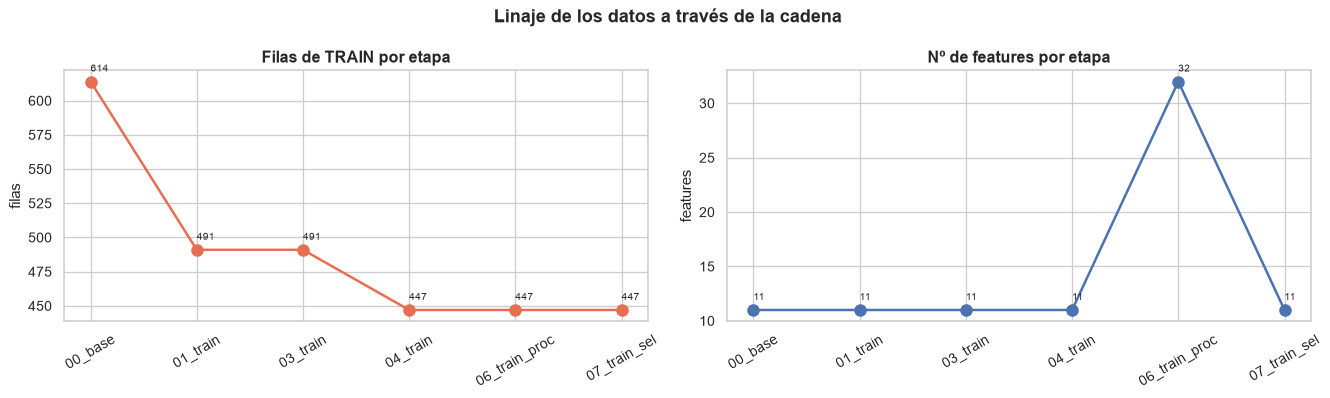

>> El test conserva sus filas en TODA la cadena (los outliers se quitan solo de train).


In [3]:
# Visualización del linaje: filas y features a lo largo de la cadena
lv = linaje.dropna(subset=["filas"])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(lv["etapa"], lv["filas"], "o-", color=COLOR_BAD, lw=2, ms=9)
axes[0].set_title("Filas de TRAIN por etapa"); axes[0].set_ylabel("filas")
axes[0].tick_params(axis="x", rotation=30)
for x, yv in zip(lv["etapa"], lv["filas"]):
    axes[0].annotate(int(yv), (x, yv), textcoords="offset points", xytext=(0, 8), fontsize=8)
axes[1].plot(lv["etapa"], lv["columnas_features"], "o-", color=COLOR_NEUTRAL, lw=2, ms=9)
axes[1].set_title("Nº de features por etapa"); axes[1].set_ylabel("features")
axes[1].tick_params(axis="x", rotation=30)
for x, yv in zip(lv["etapa"], lv["columnas_features"]):
    axes[1].annotate(int(yv), (x, yv), textcoords="offset points", xytext=(0, 8), fontsize=8)
plt.suptitle("Linaje de los datos a través de la cadena", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
print(">> El test conserva sus filas en TODA la cadena (los outliers se quitan solo de train).")

## 10.2 Resumen de decisiones de cada etapa

In [4]:
def _try(name):
    try:
        return load_report(name)
    except FileNotFoundError:
        return {}

seg = _try("segmentos"); cols = _try("columnas_descartadas"); out = _try("outliers")
iv = _try("iv_table"); sel = _try("seleccion"); bal = _try("balanceo"); pm = _try("pca_mca")

print("DECISIONES CLAVE POR ETAPA")
print("=" * 70)
print(f"01 · Segmentación : {seg.get('k_optimo','?')} segmentos, "
      f"spread de rechazo {seg.get('spread_tasa_rechazo_pp','?')} pp")
print(f"03 · Limpieza     : descartadas {len(cols.get('columnas_descartadas',[]))} columnas")
print(f"04 · Outliers     : consenso {out.get('consenso_train','?')} clientes eliminados de train")
print(f"05 · IV           : {len(iv.get('descartables_iv_bajo',[]))} vars con IV<0.02, "
      f"{len(iv.get('sospechosas_leakage',[]))} sospechosas (IV>0.5)")
print(f"07 · Selección    : {sel.get('n_despues','?')} de {sel.get('n_antes','?')} features")
print(f"08 · PCA/MCA      : PCA {pm.get('pca',{}).get('k_80','?')} comp para 80%; "
      f"MCA Dim1 {pm.get('mca',{}).get('inercia_dim',['?'])[0] if pm.get('mca') else '?'}% inercia")
print("=" * 70)

DECISIONES CLAVE POR ETAPA
01 · Segmentación : 4 segmentos, spread de rechazo 12.700000000000003 pp
03 · Limpieza     : descartadas 0 columnas
04 · Outliers     : consenso 44 clientes eliminados de train
05 · IV           : 3 vars con IV<0.02, 1 sospechosas (IV>0.5)
07 · Selección    : 11 de 32 features
08 · PCA/MCA      : PCA 4 comp para 80%; MCA Dim1 11.040897340462708% inercia


## 10.3 Inventario del pipeline desplegable

Todo lo que **aprende de los datos** está serializado en `artifacts/`. Esto —y solo esto— es lo
que se despliega a producción junto con el modelo.

In [5]:
print("ARTEFACTOS SERIALIZADOS (el pipeline desplegable):")
for p in sorted(ARTIFACTS.glob("*.joblib")):
    print(f"  · {p.name}  ({p.stat().st_size/1024:.0f} KB)")
print()
print("REPORTES DE DECISIONES (la memoria de la cadena):")
for p in sorted(REPORTS.glob("*.json")):
    print(f"  · {p.name}")

ARTEFACTOS SERIALIZADOS (el pipeline desplegable):
  · detectores.joblib  (2193 KB)
  · mca.joblib  (70 KB)
  · pca.joblib  (4 KB)
  · preprocesador.joblib  (7 KB)
  · segment_model.joblib  (4 KB)
  · woe_transformer.joblib  (15 KB)

REPORTES DE DECISIONES (la memoria de la cadena):
  · balanceo.json
  · columnas_descartadas.json
  · eda_decisiones.json
  · iv_table.json
  · outliers.json
  · pca_mca.json
  · segmentos.json
  · seleccion.json


## 10.4 Dataset final para modelado

El dataset listo para la siguiente fase (modelado) es el de la etapa 07: features seleccionadas,
sin leakage, con el metadato de segmento y el target. Lo re-exportamos con un nombre claro.

In [6]:
train_final = load_stage("07_train_sel")
test_final = load_stage("07_test_sel")

# Verificaciones finales de integridad
assert TARGET in train_final.columns and TARGET in test_final.columns
assert train_final.drop(columns=[TARGET, SEGMENT_COL]).isna().sum().sum() == 0
assert test_final.drop(columns=[TARGET, SEGMENT_COL]).isna().sum().sum() == 0
assert len(set(train_final.index) & set(test_final.index)) == 0

save_stage(train_final, "10_train_final")
save_stage(test_final, "10_test_final")

n_feat = train_final.shape[1] - 2
print("DATASET FINAL PARA MODELADO")
print("=" * 60)
print(f"  10_train_final → {train_final.shape[0]} filas × {n_feat} features")
print(f"  10_test_final  → {test_final.shape[0]} filas × {n_feat} features")
print(f"  tasa evento train: {train_final[TARGET].mean():.1%} | test: {test_final[TARGET].mean():.1%}")
print(f"  nulos: 0 | solapamiento train/test: 0")
print("=" * 60)

DATASET FINAL PARA MODELADO
  10_train_final → 447 filas × 11 features
  10_test_final  → 123 filas × 11 features
  tasa evento train: 29.1% | test: 31.7%
  nulos: 0 | solapamiento train/test: 0


In [7]:
# Guardamos el linaje completo
save_report({
    "linaje": linaje.to_dict(orient="records"),
    "dataset_final": {"train_filas": int(train_final.shape[0]),
                      "test_filas": int(test_final.shape[0]),
                      "n_features": int(n_feat)},
    "ramas_alternativas": {
        "woe": "05_train_woe (features WoE para scorecard/regresión logística)",
        "pca_mca": "08_*_coords (representación reducida)",
        "balanceado": "09_train_smote / _over / _under (solo experimentación)",
    },
}, "linaje")
save_table(linaje.set_index("etapa"), "linaje")
print("Linaje → reports/linaje.json + linaje.csv")

Linaje → reports/linaje.json + linaje.csv


## 10.5 Los 10 mandamientos del preprocesamiento

1. **Define bien el target antes de escribir código.** ¿Responde la pregunta de negocio?
2. **Divide train/test ANTES de mirar los datos.** El EDA sobre el test ya es leakage.
3. **`fit` solo en train. `transform` en ambos.** Sin excepciones. Todo lo aprendido, en `artifacts/`.
4. **Preserva el índice** (aquí, `Loan_ID`): permite rastrear cada cliente por toda la cadena.
5. **El nulo puede ser información** (MNAR). Antes de imputar, pregunta *por qué* falta.
6. **`stratify=y` no es "estratificar"**: protege el target y nada más. Estratifica por lo que importe.
7. **Ordinal → labeling · Nominal → one-hot.** Inventarle un orden a una nominal es mentirle al modelo.
8. **Un IV > 0.5 no es un logro, es una alarma** de leakage o target disfrazado.
9. **El test nunca pierde filas.** Outliers y balanceo se aplican solo a train.
10. **Cada etapa exporta lo que aprendió.** Datos por parquet, modelos por joblib, decisiones por json.

---

> ### La idea que quiero que se lleven
>
> El algoritmo es una *commodity*. **La diferencia entre un modelo que funciona y uno que fracasa
> casi nunca está en el algoritmo: está en todo lo que hicimos en estas 11 etapas, antes de
> llegar a él.**

---
<div align='center'>

**Team Futura — Data & Analítica Avanzada**

</div>

In [8]:
print("=" * 60)
print("CADENA COMPLETA. Dataset final listo para modelado.")
print("=" * 60)

CADENA COMPLETA. Dataset final listo para modelado.
